<center><h1>Jha_Ria_HW4</h1></center>
<br>
<br>


Name: Ria Jha
<br>
Github Username: riajha-usc
<br>
USC ID: 8116906970


## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)


### (a) Obtain Data


Import packages


In [1]:
import os
import re
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, accuracy_score)

warnings.filterwarnings("ignore")

Get the AReM Data Set


In [2]:
ZIP_PATH = "AReM.zip"
BASE = "AReM"

with zipfile.ZipFile(ZIP_PATH) as zf:
    members = [m for m in zf.namelist() if not m.startswith("__MACOSX")]
    zf.extractall(".", members=members)

cols = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

def load_file(path):
    rows = []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            tokens = [t for t in re.split(r"[,\s]+", line) if t != ""]
            if len(tokens) < 7:
                continue
            try:
                rows.append([float(t) for t in tokens[1:7]])
            except ValueError:
                continue
    return pd.DataFrame(rows, columns=cols)

records = []
for activity in sorted(os.listdir(BASE)):
    folder = os.path.join(BASE, activity)
    if not os.path.isdir(folder):
        continue
    for fname in sorted(os.listdir(folder)):
        if not fname.endswith(".csv"):
            continue
        num = int(re.findall(r"\d+", fname)[0])
        test_ids = (1, 2) if activity in ("bending1", "bending2") else (1, 2, 3)
        records.append({
            "activity": activity,
            "num": num,
            "is_test": num in test_ids,
            "data": load_file(os.path.join(folder, fname)),
        })

print(len(records), {r["data"].shape for r in records})

88 {(479, 6), (480, 6)}


### (b) Splitting Data


In [3]:
train_recs = [r for r in records if not r["is_test"]]
test_recs = [r for r in records if r["is_test"]]

train_series = [r["data"] for r in train_recs]
test_series = [r["data"] for r in test_recs]

act_train = np.array([r["activity"] for r in train_recs])
act_test = np.array([r["activity"] for r in test_recs])
y_train = np.array([a.startswith("bending") for a in act_train]).astype(int)
y_test = np.array([a.startswith("bending") for a in act_test]).astype(int)

print("train:", len(train_recs), "| test:", len(test_recs))
print("bending in train:", y_train.sum(), "of", len(y_train), "| bending in test:", y_test.sum(), "of", len(y_test))

train: 69 | test: 19
bending in train: 9 of 69 | bending in test: 4 of 19


### (c) Feature Extraction


In [4]:
STATS = {
    "min": np.min,
    "max": np.max,
    "mean": np.mean,
    "median": np.median,
    "std": lambda a: np.std(a, ddof=1),
    "q1": lambda a: np.quantile(a, 0.25),
    "q3": lambda a: np.quantile(a, 0.75),
}

def make_features(series_list, l=1):
    rows = []
    for df in series_list:
        feats = {}
        for s, col in enumerate(df.columns, start=1):
            for k, seg in enumerate(np.array_split(df[col].to_numpy(), l), start=1):
                tag = "" if l == 1 else f"_p{k}"
                for name, f in STATS.items():
                    feats[f"{name}{s}{tag}"] = f(seg)
        rows.append(feats)
    return pd.DataFrame(rows)

all_features = make_features([r["data"] for r in records], 1)
X1_train = make_features(train_series, 1)
X1_test = make_features(test_series, 1)

print(all_features.shape, X1_train.shape, X1_test.shape)
all_features.head()

(88, 42) (69, 42) (19, 42)


,min1,max1,mean1,median1,std1,q11,q31,min2,max2,mean2,...,std5,q15,q35,min6,max6,mean6,median6,std6,q16,q36
0,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,1.30,0.358604,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,1.22,0.372437,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


## 2. Time Series Classification Part 2: Binary and Multiclass Classification


### (a) Binary Classification Using Logistic Regression


#### i. Plots


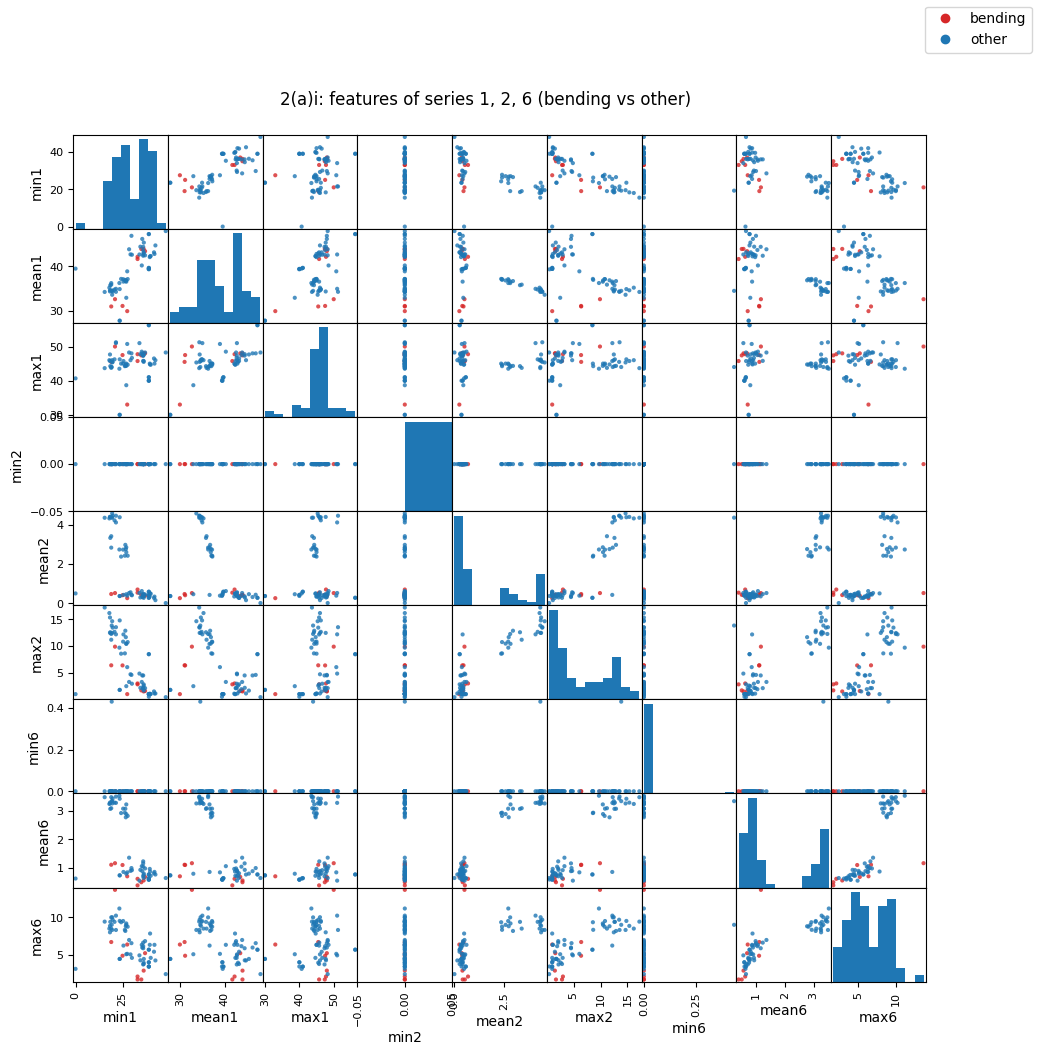

In [5]:
chosen = ["min", "mean", "max"]
series_ids = (1, 2, 6)

def scatter_by_class(df, y, title):
    colors = np.where(y == 1, "tab:red", "tab:blue")
    pd.plotting.scatter_matrix(df, c=colors, figsize=(11, 11), alpha=0.8, diagonal="hist")
    handles = [plt.Line2D([], [], marker="o", ls="", color="tab:red", label="bending"),
               plt.Line2D([], [], marker="o", ls="", color="tab:blue", label="other")]
    plt.gcf().legend(handles=handles, loc="upper right")
    plt.suptitle(title, y=0.92)
    plt.show()

cols_i = [f"{s}{k}" for k in series_ids for s in chosen]
scatter_by_class(X1_train[cols_i], y_train, "2(a)i: features of series 1, 2, 6 (bending vs other)")

The bending points (red) sit at low values of mean2, max2 and mean6, but the lying, sitting and standing instances sit in the same region, so no single pair of features separates bending from the rest. Cycling and walking are the only activities that are clearly apart from bending. The min2 and min6 panels are flat lines, because min2 is 0 for every instance and min6 is almost constant, so those two features carry no information.


#### ii. Splitted Plots


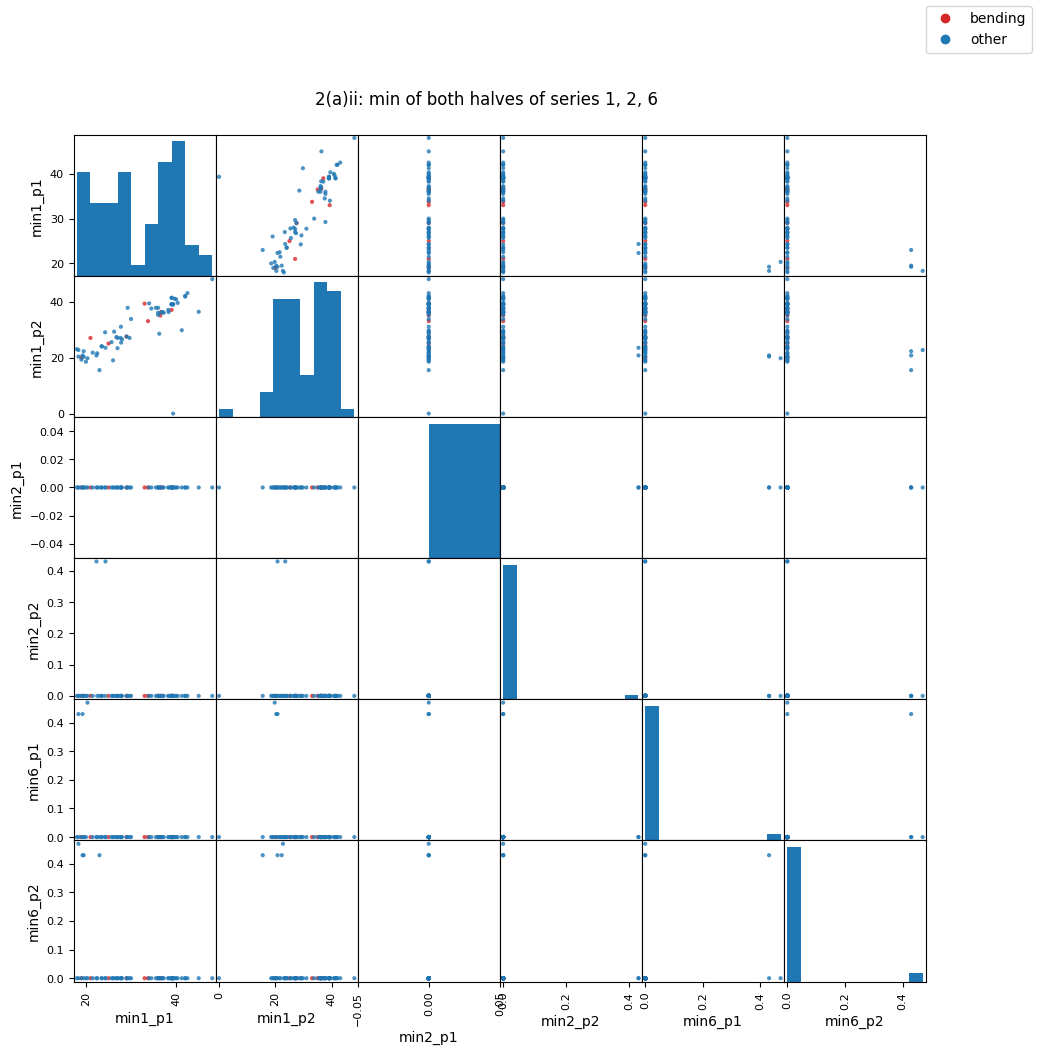

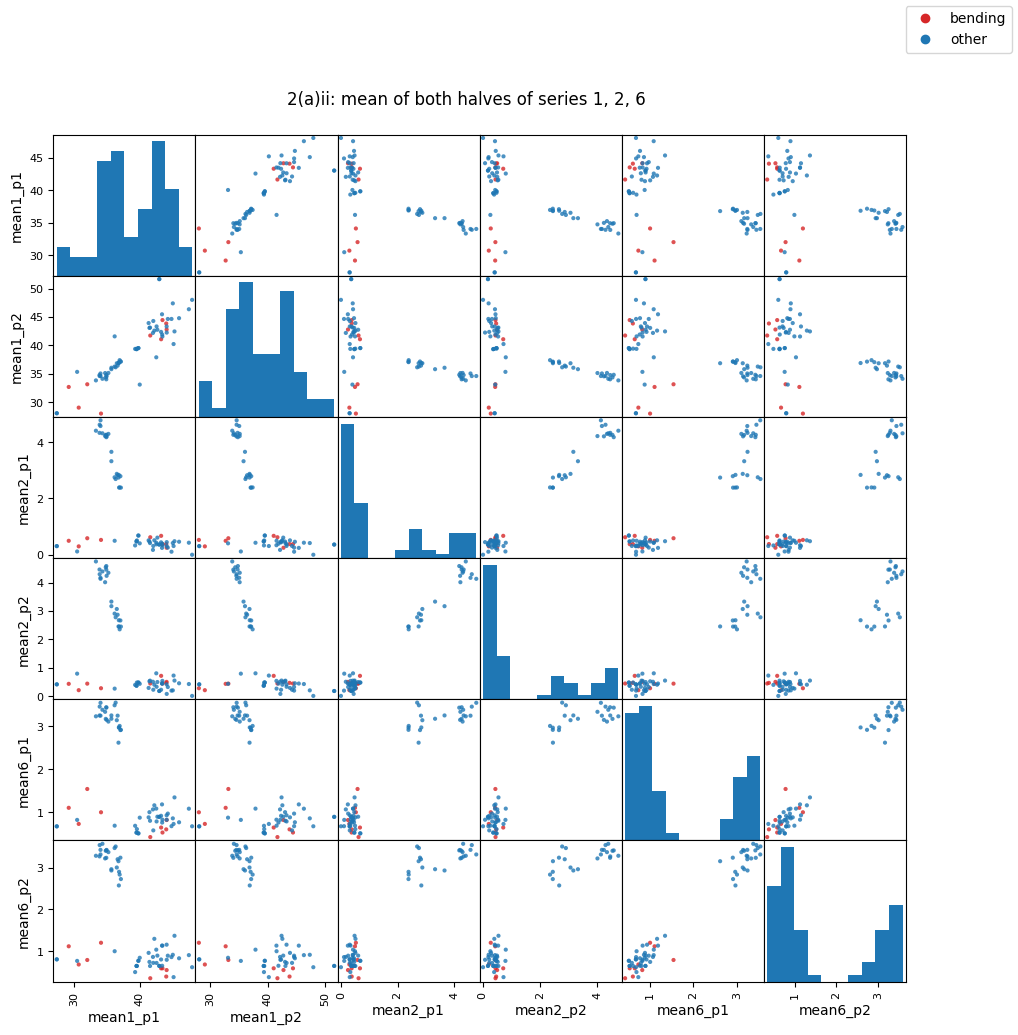

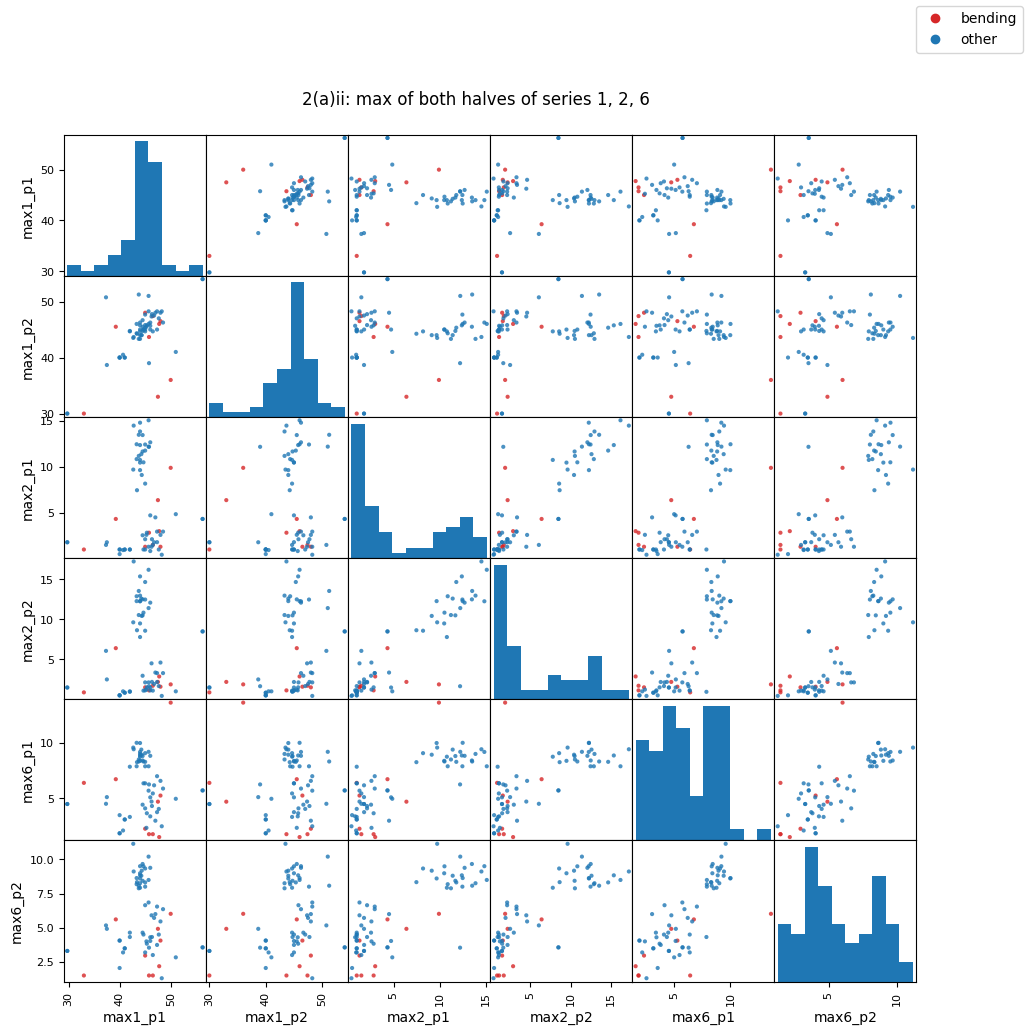

In [6]:
X2_train = make_features(train_series, 2)

for s in chosen:
    cols_ii = [f"{s}{k}_p{j}" for k in series_ids for j in (1, 2)]
    scatter_by_class(X2_train[cols_ii], y_train, f"2(a)ii: {s} of both halves of series 1, 2, 6")

There is no considerable difference from 2(a)i. Plotting the first half of a series against the second half puts the points along a diagonal (for example mean1_p1 against mean1_p2), so the two halves carry almost the same information. The bending points stay in the same low-variability region, and the min panels for series 2 and 6 are still flat. Each activity is roughly stationary over the recording, so splitting each series into two parts adds very little.


#### iii. Time Series Segments


In [7]:
L_RANGE = range(1, 21)
P_GRID = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 30, 40]
LR_KW = dict(C=1e6, max_iter=500)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

feats_train = {l: make_features(train_series, l) for l in L_RANGE}
feats_test = {l: make_features(test_series, l) for l in L_RANGE}

def rfe_ranking(X, y):
    sc = StandardScaler().fit(X)
    rfe = RFE(LogisticRegression(**LR_KW), n_features_to_select=1, step=1).fit(sc.transform(X), y)
    return sc, rfe.ranking_

cv_rows = []
for l in L_RANGE:
    X = feats_train[l].to_numpy()
    grid = [p for p in P_GRID if p <= X.shape[1]]
    acc = {p: [] for p in grid}
    for tr, va in skf.split(X, y_train):
        sc, rank = rfe_ranking(X[tr], y_train[tr])
        Xtr, Xva = sc.transform(X[tr]), sc.transform(X[va])
        for p in grid:
            keep = rank <= p
            m = LogisticRegression(**LR_KW).fit(Xtr[:, keep], y_train[tr])
            acc[p].append(m.score(Xva[:, keep], y_train[va]))
    for p in grid:
        cv_rows.append({"l": l, "p": p, "cv_acc": np.mean(acc[p])})

cv_table = pd.DataFrame(cv_rows)
ranked = cv_table.sort_values(["cv_acc", "l", "p"], ascending=[False, True, True])
best_l, best_p = int(ranked.iloc[0].l), int(ranked.iloc[0].p)
best_cv_acc = ranked.iloc[0].cv_acc

print("best (l, p):", (best_l, best_p), "| CV accuracy:", round(best_cv_acc, 4))
display(cv_table.pivot(index="l", columns="p", values="cv_acc").round(3))

best (l, p): (1, 4) | CV accuracy: 0.9857


p,1,2,3,4,5,6,8,10,12,15,20,30,40
l,,,,,,,,,,,,,
1,0.913,0.943,0.985,0.986,0.986,0.971,0.971,0.986,0.986,0.970,0.986,0.957,0.957
2,0.913,0.956,0.971,0.986,0.957,0.943,0.943,0.957,0.957,0.943,0.942,0.899,0.899
3,0.926,0.957,0.957,0.927,0.957,0.943,0.929,0.929,0.929,0.927,0.927,0.913,0.913
4,0.957,0.912,0.899,0.899,0.929,0.929,0.943,0.929,0.913,0.913,0.927,0.927,0.913
5,0.943,0.942,0.942,0.942,0.957,0.957,0.957,0.943,0.929,0.929,0.943,0.929,0.927
6,0.914,0.942,0.943,0.943,0.943,0.957,0.927,0.942,0.942,0.942,0.957,0.957,0.957
7,0.957,0.927,0.912,0.913,0.929,0.913,0.943,0.943,0.929,0.929,0.943,0.913,0.929
8,0.913,0.898,0.899,0.899,0.913,0.929,0.929,0.929,0.943,0.929,0.929,0.913,0.899
9,0.898,0.884,0.913,0.899,0.943,0.943,0.912,0.927,0.912,0.927,0.899,0.899,0.899


I cross-validated the pair (l, p) with 5-fold stratified CV, where l is the number of segments per series (1 to 20) and p is the number of features kept by recursive feature elimination (RFE), a backward-selection method. Stratification keeps at least one of the 9 bending instances in every fold.

**Right way:** inside each fold, fit the scaler and the RFE ranking on that fold's training part only, then score the held-out part using only the features chosen from the training part. The choice of l and p is evaluated the same way.

**Wrong way:** rank or select features on all 69 training instances first, then cross-validate. The held-out labels would already have influenced which features were kept, so the CV accuracy comes out too optimistic.

The best pair is (l, p) = (1, 4) with CV accuracy 0.9857, and several pairs tie at that value, so I took the smallest l and then the smallest p. Larger l lowers CV accuracy: at l = 20 there are 840 features for 69 instances, which is too many for the amount of data. The selected features are q31, min5, max5 and q16.


#### iv. Confusion Matrix


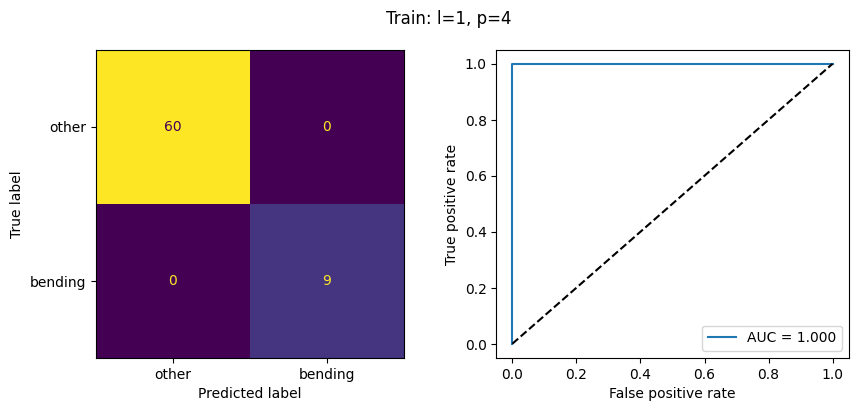

selected features: ['q31', 'min5', 'max5', 'q16']


,beta,std_err,p_value
intercept,-13.8072,19.3711,0.4760
q31,-5.1550,15.2916,0.7360
min5,8.2741,20.6468,0.6886
max5,8.3263,14.6608,0.5701
q16,-3.7894,20.1529,0.8509


In [8]:
def show_binary(y, pred, score, title):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=["other", "bending"]).plot(ax=axes[0], colorbar=False)
    fpr, tpr, _ = roc_curve(y, score)
    axes[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y, score):.3f}")
    axes[1].plot([0, 1], [0, 1], "k--")
    axes[1].set_xlabel("False positive rate")
    axes[1].set_ylabel("True positive rate")
    axes[1].legend()
    fig.suptitle(title)
    plt.show()

def wald_table(model, X, names):
    Xd = np.column_stack([np.ones(len(X)), X])
    beta = np.r_[model.intercept_, model.coef_.ravel()]
    mu = 1 / (1 + np.exp(-Xd @ beta))
    cov = np.linalg.pinv(Xd.T @ (Xd * (mu * (1 - mu))[:, None]))
    se = np.sqrt(np.diag(cov))
    z = beta / se
    return pd.DataFrame({"beta": beta, "std_err": se, "p_value": 2 * (1 - norm.cdf(np.abs(z)))},
                        index=["intercept"] + list(names))

Xtr_df, Xte_df = feats_train[best_l], feats_test[best_l]
scaler, rank = rfe_ranking(Xtr_df.to_numpy(), y_train)
keep = rank <= best_p
sel_names = Xtr_df.columns[keep]

Xtr_s = scaler.transform(Xtr_df.to_numpy())[:, keep]
Xte_s = scaler.transform(Xte_df.to_numpy())[:, keep]

final = LogisticRegression(**LR_KW).fit(Xtr_s, y_train)

train_score = final.predict_proba(Xtr_s)[:, 1]
show_binary(y_train, final.predict(Xtr_s), train_score, f"Train: l={best_l}, p={best_p}")

print("selected features:", list(sel_names))
display(wald_table(final, Xtr_s, sel_names).round(4))

On the training set the confusion matrix is [[60, 0], [0, 9]], so there are no errors, and the AUC is 1.000. The features were standardized, so each coefficient is the change in log-odds per one standard deviation.

| Term      | β        | Std. error | p-value |
| --------- | -------- | ---------- | ------- |
| intercept | -13.8072 | 19.3711    | 0.4760  |
| q31       | -5.1550  | 15.2916    | 0.7360  |
| min5      | 8.2741   | 20.6468    | 0.6886  |
| max5      | 8.3263   | 14.6608    | 0.5701  |
| q16       | -3.7894  | 20.1529    | 0.8509  |


#### v. Test Classifier


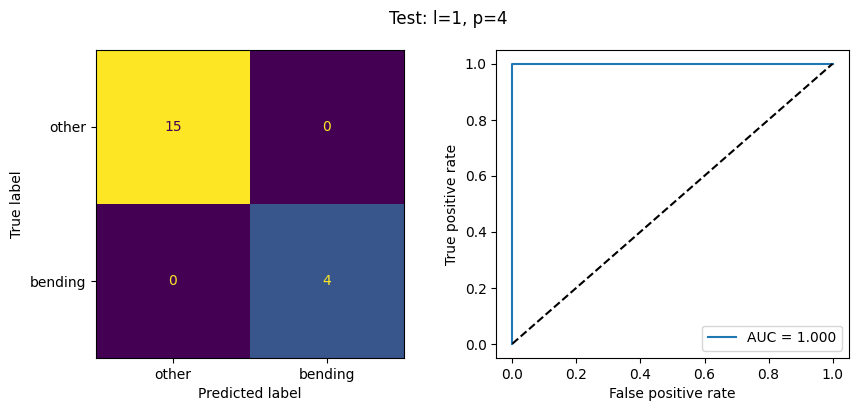

test accuracy: 1.0
CV accuracy:   0.9857
train accuracy: 1.0


In [9]:
test_pred = final.predict(Xte_s)
test_score = final.predict_proba(Xte_s)[:, 1]

show_binary(y_test, test_pred, test_score, f"Test: l={best_l}, p={best_p}")

print("test accuracy:", round(accuracy_score(y_test, test_pred), 4))
print("CV accuracy:  ", round(best_cv_acc, 4))
print("train accuracy:", round(final.score(Xtr_s, y_train), 4))

The test confusion matrix is [[15, 0], [0, 4]], with test accuracy 1.0 and AUC 1.000. This is slightly above the cross-validation accuracy of 0.9857, and the training accuracy is also 1.0, so there is no sign of overfitting. The test set has only 19 instances (4 bending), so one wrong prediction would change the accuracy by about 5%, and the test accuracy is a coarse estimate.


#### vi. Separation


In [10]:
sep_rows = []
for C in [1, 1e2, 1e4, 1e6, 1e8]:
    m = LogisticRegression(C=C, max_iter=5000).fit(Xtr_s, y_train)
    sep_rows.append({"C": C, "train_acc": m.score(Xtr_s, y_train),
                     "train_auc": roc_auc_score(y_train, m.decision_function(Xtr_s)),
                     "max_abs_coef": np.abs(m.coef_).max()})
display(pd.DataFrame(sep_rows))

tbl = wald_table(final, Xtr_s, sel_names)
print("smallest p-value among features:", tbl["p_value"].iloc[1:].min().round(4))
print("largest standard error:", tbl["std_err"].max().round(2))

,C,train_acc,train_auc,max_abs_coef
0,1.0,1.0,1.0,1.688971
1,100.0,1.0,1.0,5.359754
2,10000.0,1.0,1.0,8.228925
3,1000000.0,1.0,1.0,8.326250
4,100000000.0,1.0,1.0,8.327251


smallest p-value among features: 0.5701
largest standard error: 20.65


Yes, the classes are separated. For every value of C from 1 to 1e8 the training accuracy and AUC are both 1.0, which means a hyperplane splits bending from the other activities exactly. When that happens the likelihood keeps increasing as the coefficients grow, so the unpenalized maximum likelihood estimate does not exist, and the fit only stops at the solver's iteration limit. The coefficients grow with C (the largest goes from 1.69 at C = 1 to about 8.3), the standard errors are very large (up to 20.65), and every p-value is above 0.5.

The p-values are therefore unreliable here. As the assignment suggests, I capped max_iter so the solver stops early, and I selected features with RFE, which ranks by coefficient size, instead of relying on these p-values.


#### vii. Imbalance


train class counts (other, bending): [60  9]
test class counts (other, bending):  [15  4]


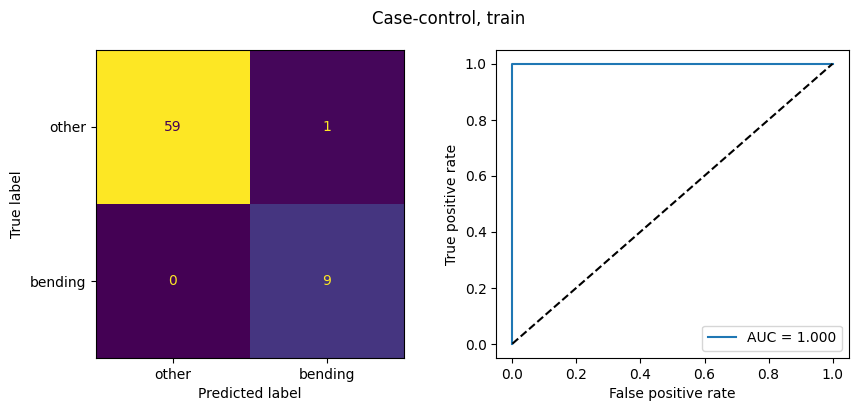

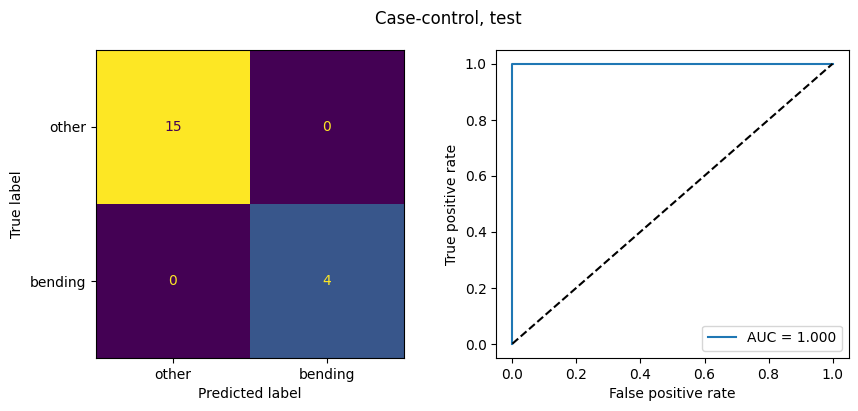

,beta,std_err,p_value
intercept,-9.0530,61.4658,0.8829
q31,-1.4430,30.4088,0.9622
min5,6.1657,33.3219,0.8532
max5,5.8289,31.3473,0.8525
q16,-6.6737,59.2844,0.9104


In [11]:
print("train class counts (other, bending):", np.bincount(y_train))
print("test class counts (other, bending): ", np.bincount(y_test))

rng = np.random.default_rng(0)
pos = np.where(y_train == 1)[0]
neg = np.where(y_train == 0)[0]
idx = np.r_[pos, rng.choice(neg, size=len(pos), replace=False)]

cc = LogisticRegression(**LR_KW).fit(Xtr_s[idx], y_train[idx])
pi = y_train.mean()
cc.intercept_ = cc.intercept_ + np.log(pi / (1 - pi))

show_binary(y_train, cc.predict(Xtr_s), cc.predict_proba(Xtr_s)[:, 1], "Case-control, train")
show_binary(y_test, cc.predict(Xte_s), cc.predict_proba(Xte_s)[:, 1], "Case-control, test")

display(wald_table(cc, Xtr_s[idx], sel_names).round(4))

Yes, the classes are imbalanced: 60 other vs 9 bending in the training set (13% bending), and 15 vs 4 in the test set. The confusion matrices show no errors, so the imbalance has no visible cost here, but a classifier that always predicts "other" would already score 87%.

I built a case-control model: all 9 bending instances plus 9 randomly chosen other instances, so the sample is balanced. Sampling this way inflates the intercept, so I corrected it by adding log(π / (1 - π)) = log(9 / 60) = -1.897, where π = 9/69 is the bending fraction in the training set. On the training set the confusion matrix is [[59, 1], [0, 9]] (one false positive), and on the test set it is [[15, 0], [0, 4]]. The AUC is 1.000 on the test set, the same as the unweighted model.


### (b) Binary Classification Using L1-penalized logistic regression


#### i. Time Series Segments


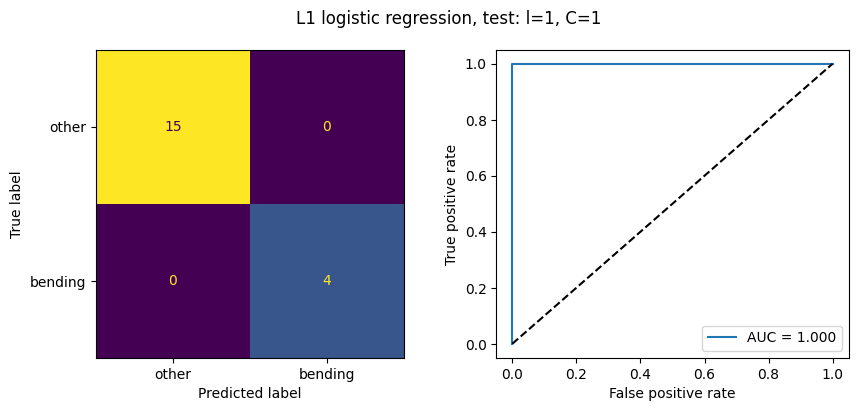

,l,best_C,cv_acc
0,1,1.000,0.986
1,2,4.642,0.971
2,3,0.464,0.971
3,4,21.544,0.943
4,5,10.000,0.942
5,6,46.416,0.971
6,7,100.000,0.956
7,8,4.642,0.929
8,9,4.642,0.927
9,10,46.416,0.942


In [12]:
C_GRID = np.logspace(-2, 2, 13)

def l1_pipe(C=1.0):
    return make_pipeline(StandardScaler(), LogisticRegression(penalty="l1", solver="liblinear", C=C, max_iter=1000, random_state=0))

l1_rows = []
for l in L_RANGE:
    gs = GridSearchCV(l1_pipe(), {"logisticregression__C": C_GRID}, cv=skf, scoring="accuracy")
    gs.fit(feats_train[l], y_train)
    l1_rows.append({"l": l, "best_C": gs.best_params_["logisticregression__C"], "cv_acc": gs.best_score_})

l1_table = pd.DataFrame(l1_rows)
top = l1_table.sort_values(["cv_acc", "l"], ascending=[False, True]).iloc[0]
l1_l, l1_C, l1_cv = int(top.l), float(top.best_C), float(top.cv_acc)

l1_model = l1_pipe(l1_C).fit(feats_train[l1_l], y_train)
l1_pred = l1_model.predict(feats_test[l1_l])
l1_score = l1_model.predict_proba(feats_test[l1_l])[:, 1]

show_binary(y_test, l1_pred, l1_score, f"L1 logistic regression, test: l={l1_l}, C={l1_C:.3g}")

display(l1_table.round(3))

I cross-validated l (1 to 20) and the L1 budget C (13 values from 0.01 to 100) with 5-fold stratified CV, using standardized features inside the pipeline. The best choice is l = 1 with C = 1, CV accuracy 0.9857, and 7 non-zero coefficients. On the test set the accuracy is 1.0 and the AUC is 1.000.


#### ii. Comparison


In [13]:
n_nonzero = int((l1_model[-1].coef_ != 0).sum())

compare = pd.DataFrame([
    {"method": "RFE + logistic regression", "l": best_l, "n_features": best_p,
     "cv_acc": best_cv_acc, "test_acc": accuracy_score(y_test, test_pred),
     "test_auc": roc_auc_score(y_test, test_score)},
    {"method": "L1-penalized logistic regression", "l": l1_l, "n_features": n_nonzero,
     "cv_acc": l1_cv, "test_acc": accuracy_score(y_test, l1_pred),
     "test_auc": roc_auc_score(y_test, l1_score)},
])
compare.round(4)

,method,l,n_features,cv_acc,test_acc,test_auc
0,RFE + logistic regression,1,4,0.9857,1.0,1.0
1,L1-penalized logistic regression,1,7,0.9857,1.0,1.0


Both methods perform the same here: l = 1, CV accuracy 0.9857, test accuracy 1.0 and test AUC 1.0. RFE keeps 4 features and L1 keeps 7, so RFE gives the smaller model. L1 is easier to implement. It needs one GridSearchCV over (l, C), while the RFE approach needs a manual loop that refits the scaler and RFE inside every fold, and sklearn does not report p-values at all. L1 is also better behaved when the classes are separated, because the penalty keeps the coefficients finite, while the p-values from the unpenalized fit are unreliable (see 2(a)vi).


### (c) Multi-class Classification (The Realistic Case)


#### i. Time Series Segments


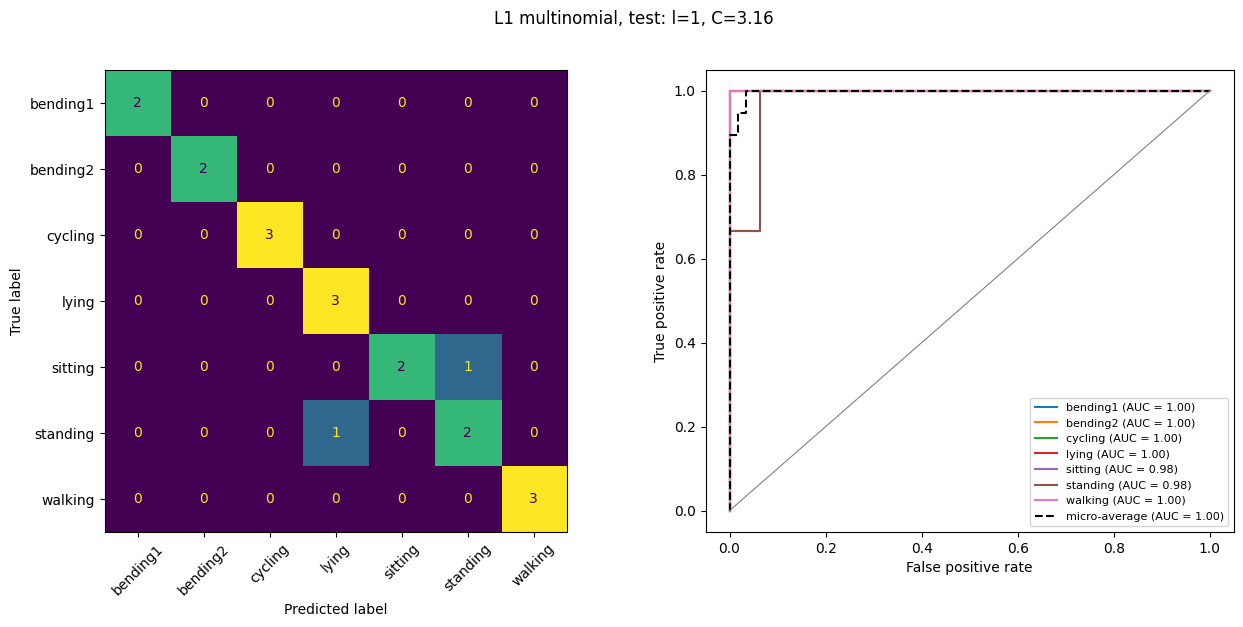

best l: 1 | C: 3.162 | CV accuracy: 0.9571
test error: 0.1053 | macro AUC: 0.994


,l,best_C,cv_acc
0,1,3.162,0.957
1,2,10.000,0.884
2,3,3.162,0.869
3,4,100.000,0.885
4,5,10.000,0.869
5,6,3.162,0.840
6,7,10.000,0.840
7,8,31.623,0.825
8,9,3.162,0.826
9,10,31.623,0.825


In [14]:
class_names = list(np.unique(act_train))
MC_C = np.logspace(-1, 2, 7)

def report_multiclass(model, X_te, y_te, title):
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)
    Y = label_binarize(y_te, classes=class_names)
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    ConfusionMatrixDisplay(confusion_matrix(y_te, pred, labels=class_names), display_labels=class_names).plot(
        ax=axes[0], colorbar=False, xticks_rotation=45)
    for i, c in enumerate(class_names):
        fpr, tpr, _ = roc_curve(Y[:, i], proba[:, i])
        axes[1].plot(fpr, tpr, label=f"{c} (AUC = {roc_auc_score(Y[:, i], proba[:, i]):.2f})")
    fpr, tpr, _ = roc_curve(Y.ravel(), proba.ravel())
    axes[1].plot(fpr, tpr, "k--", label=f"micro-average (AUC = {roc_auc_score(Y, proba, average='micro'):.2f})")
    axes[1].plot([0, 1], [0, 1], color="gray", lw=0.8)
    axes[1].set_xlabel("False positive rate")
    axes[1].set_ylabel("True positive rate")
    axes[1].legend(fontsize=8)
    fig.suptitle(title)
    plt.show()
    return {"test_error": 1 - accuracy_score(y_te, pred), "macro_auc": roc_auc_score(Y, proba, average="macro")}

def mn_pipe(C=1.0):
    return make_pipeline(StandardScaler(), LogisticRegression(penalty="l1", solver="saga", C=C, max_iter=3000, tol=1e-3, random_state=0))

mc_rows = []
for l in L_RANGE:
    gs = GridSearchCV(mn_pipe(), {"logisticregression__C": MC_C}, cv=skf, scoring="accuracy", n_jobs=-1)
    gs.fit(feats_train[l], act_train)
    mc_rows.append({"l": l, "best_C": gs.best_params_["logisticregression__C"], "cv_acc": gs.best_score_})

mc_table = pd.DataFrame(mc_rows)
top = mc_table.sort_values(["cv_acc", "l"], ascending=[False, True]).iloc[0]
mc_l, mc_C, mc_cv = int(top.l), float(top.best_C), float(top.cv_acc)

mc_model = mn_pipe(mc_C).fit(feats_train[mc_l], act_train)
mc_res = report_multiclass(mc_model, feats_test[mc_l], act_test, f"L1 multinomial, test: l={mc_l}, C={mc_C:.3g}")

print("best l:", mc_l, "| C:", round(mc_C, 3), "| CV accuracy:", round(mc_cv, 4))
print("test error:", round(mc_res["test_error"], 4), "| macro AUC:", round(mc_res["macro_auc"], 4))
display(mc_table.round(3))

Cross-validating l and C for an L1-penalized multinomial logistic regression (saga solver) gives l = 1, C = 3.16 and CV accuracy 0.9571. The test error is 0.1053, which is 2 of 19 instances wrong: one sitting predicted as standing and one standing predicted as lying. The macro-average AUC is 0.994.

For K classes the confusion matrix is K x K, with true classes in the rows and predicted classes in the columns. ROC curves are defined one class at a time: treat class k as positive and all other classes as negative, using the predicted probability of class k, then average the curves (micro or macro) for a single summary. Sitting and standing have the lowest AUC (0.98), and the other five classes have AUC 1.00.


#### ii. Naive Bayes


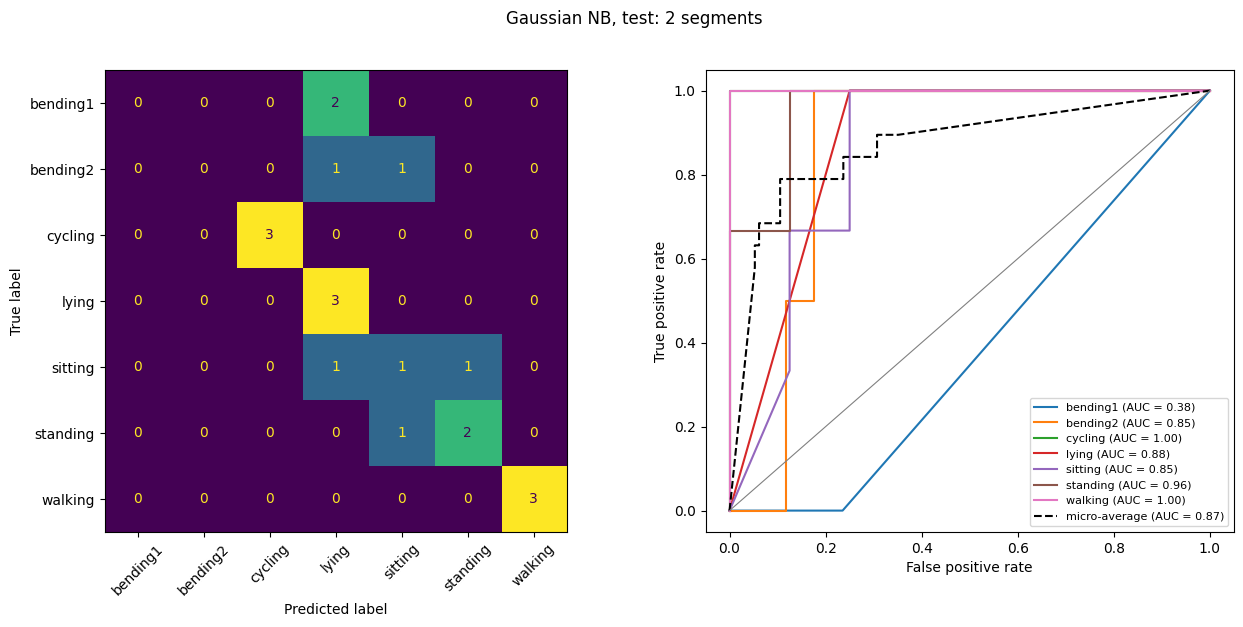

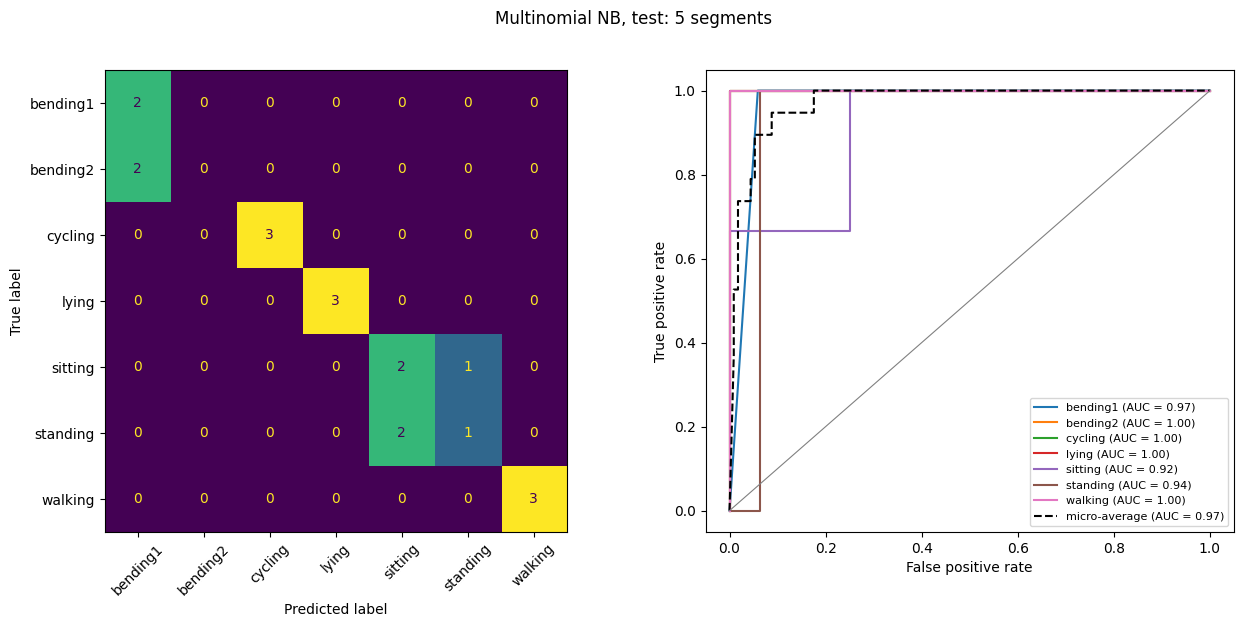

,model,l,cv_acc,test_error,macro_auc
0,L1 multinomial logistic,1,0.9571,0.1053,0.9940
1,Gaussian NB,2,0.8264,0.3684,0.8461
2,Multinomial NB,5,0.8407,0.2632,0.9750


In [15]:
nb_summary = [{"model": "L1 multinomial logistic", "l": mc_l, "cv_acc": mc_cv, **mc_res}]

for name, cls in {"Gaussian NB": GaussianNB, "Multinomial NB": MultinomialNB}.items():
    cv_scores = {l: cross_val_score(cls(), feats_train[l], act_train, cv=skf).mean() for l in L_RANGE}
    nb_l = min(cv_scores, key=lambda l: (-cv_scores[l], l))
    nb_model = cls().fit(feats_train[nb_l], act_train)
    res = report_multiclass(nb_model, feats_test[nb_l], act_test, f"{name}, test: {nb_l} segments")
    nb_summary.append({"model": name, "l": nb_l, "cv_acc": cv_scores[nb_l], **res})

pd.DataFrame(nb_summary).round(4)

For each model I chose l by 5-fold stratified CV.

| Model          | Best l | CV accuracy | Test error | Macro AUC |
| -------------- | ------ | ----------- | ---------- | --------- |
| Gaussian NB    | 2      | 0.8264      | 0.3684     | 0.8461    |
| Multinomial NB | 5      | 0.8407      | 0.2632     | 0.9750    |

Gaussian NB predicts both bending classes as lying or sitting (7 of 19 wrong). Multinomial NB mostly confuses bending2 with bending1 (the right family of activity) and sitting with standing (5 of 19 wrong). Multinomial NB can be used here only because all the features are non-negative.


#### ii. Comparison


The L1-penalized multinomial regression is the best method: it has the lowest test error (0.105, against 0.263 for Multinomial NB and 0.368 for Gaussian NB), the highest CV accuracy (0.957, against 0.84 and 0.83) and the highest macro AUC (0.994). Naive Bayes assumes the features are independent given the class, and here they are strongly dependent: min, mean, median and the quartiles of one series all move together. Gaussian NB also assumes normal features within each class, and Multinomial NB assumes count-like features, which is only a rough fit for RSS statistics. The L1 model learns discriminative weights and drops redundant features.


## 3. ISLR 4.8.3


For one feature and K classes, X | Y = k ~ N(mu_k, sigma_k^2) with prior pi_k. By Bayes' theorem

$$p_k(x)=\frac{\pi_k\frac{1}{\sqrt{2\pi}\sigma_k}\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right)}{\sum_{l=1}^{K}\pi_l\frac{1}{\sqrt{2\pi}\sigma_l}\exp\left(-\frac{(x-\mu_l)^2}{2\sigma_l^2}\right)}.$$

The Bayes classifier assigns x to the class with the largest p_k(x). The denominator is the same for every k, so it can be dropped. Taking the log of the numerator and removing the constant $-\tfrac12\log 2\pi$ gives the discriminant

$$\delta_k(x)=\log\pi_k-\log\sigma_k-\frac{(x-\mu_k)^2}{2\sigma_k^2}=-\frac{1}{2\sigma_k^2}x^2+\frac{\mu_k}{\sigma_k^2}x-\frac{\mu_k^2}{2\sigma_k^2}+\log\pi_k-\log\sigma_k .$$

This is a quadratic function of x, and the coefficient of $x^2$ is $-1/(2\sigma_k^2)$, which depends on k. The boundary between classes k and l is where $\delta_k(x)=\delta_l(x)$, that is

$$\left(\frac{1}{2\sigma_l^2}-\frac{1}{2\sigma_k^2}\right)x^2+\left(\frac{\mu_k}{\sigma_k^2}-\frac{\mu_l}{\sigma_l^2}\right)x+c=0,$$

a quadratic equation in x whenever $\sigma_k\neq\sigma_l$. So the Bayes classifier is not linear; it is quadratic. In LDA the variances are equal, so the $x^2$ terms are identical for every class and cancel in the comparison, which leaves a linear boundary.


## 4. ISLR 4.8.7


Let Y = Yes if the company issues a dividend. We know pi_Yes = 0.8, pi_No = 0.2, mu_Yes = 10, mu_No = 0 and sigma^2 = 36 (so sigma = 6). By Bayes' theorem with normal densities,

$$P(\text{Yes}\mid X=4)=\frac{\pi_{Yes}\,e^{-(4-10)^2/72}}{\pi_{Yes}\,e^{-(4-10)^2/72}+\pi_{No}\,e^{-(4-0)^2/72}}$$

The common factor $1/(\sqrt{2\pi}\,\sigma)$ cancels. Step by step:

- Yes exponent: $-(4-10)^2/72 = -36/72 = -0.5$, so $e^{-0.5} = 0.6065$.
- No exponent: $-(4-0)^2/72 = -16/72 = -0.2222$, so $e^{-0.2222} = 0.8007$.
- Numerator: $0.8 \times 0.6065 = 0.4852$.
- Second term: $0.2 \times 0.8007 = 0.1601$.
- Denominator: $0.4852 + 0.1601 = 0.6454$.
- Probability: $0.4852 / 0.6454 = 0.752$.

The probability that the company issues a dividend is about 0.752, or 75.2%.
